# HW2 : Convergence uniforme et limites de l'apprentissage

*M2 IM – IMDS – MIAGE · Statistical and Machine Learning*

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import erfc

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True

## Partie I – Simuler la convergence uniforme

### Question 1 

Pour une hypothèse $h_j$ de vrai risque $p_j$, le nombre d'erreurs sur un échantillon de taille $m$ suit $\text{Bin}(m, p_j)$, et $L_S(h_j) = E_j / m$. La théorie prédit

$$\mathbb{E}[L_S(h_j)] = p_j, \qquad \text{écart-type}(L_S(h_j)) = \sqrt{\frac{p_j(1-p_j)}{m}}.$$

Je tire $E_j$ 10 000 fois pour $m \in \{10, 50, 200, 1000\}$ avec $p_j = 0{,}3$, puis, avec $m = 200$, pour $p_j \in \{0{,}1 ; 0{,}3 ; 0{,}5\}$. Pour chaque cas je compare moyenne et écart-type empiriques aux valeurs théoriques.

=== Question 1(d) : Comparaison Moyenne Empirique vs Vrai Risque (p_j = 0.3) ===
Taille m =   10 | Moyenne empirique de L_S = 0.2972 | Vrai risque p_j = 0.3000 | Écart-type emp. = 0.1433 (Théo = 0.1449)
Taille m =   50 | Moyenne empirique de L_S = 0.3011 | Vrai risque p_j = 0.3000 | Écart-type emp. = 0.0652 (Théo = 0.0648)
Taille m =  200 | Moyenne empirique de L_S = 0.3000 | Vrai risque p_j = 0.3000 | Écart-type emp. = 0.0321 (Théo = 0.0324)
Taille m = 1000 | Moyenne empirique de L_S = 0.3000 | Vrai risque p_j = 0.3000 | Écart-type emp. = 0.0144 (Théo = 0.0145)


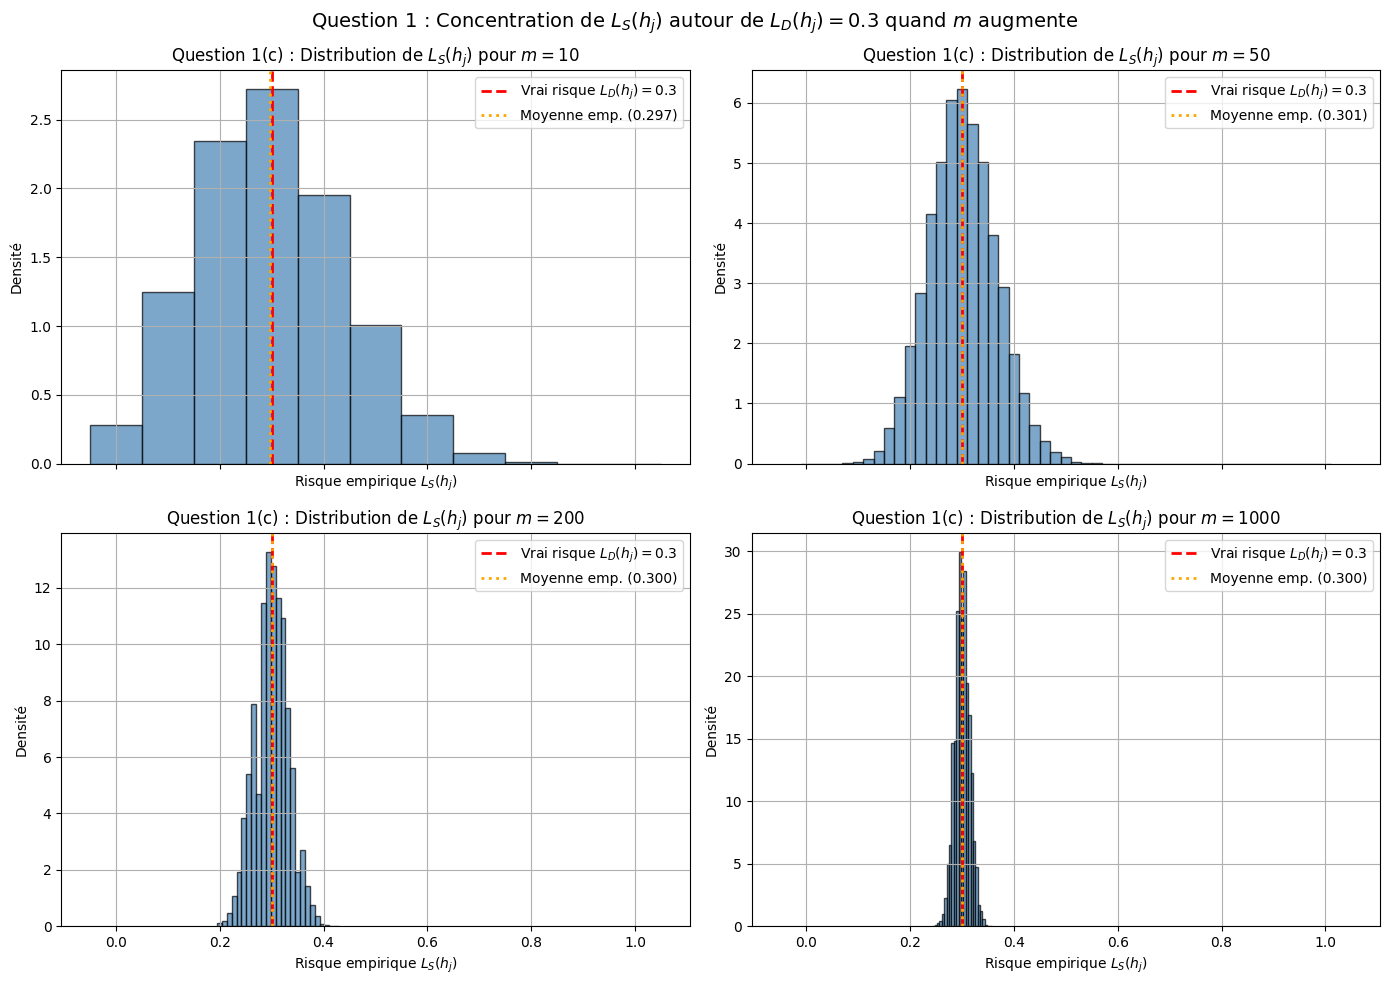


=== Question 1(d) : Vérification pour plusieurs risques p_1, ..., p_K (m = 200) ===
Vrai risque p_j = 0.10 | Moyenne empirique = 0.1001 | Écart-type emp. = 0.0210 (Théo = 0.0212)
Vrai risque p_j = 0.30 | Moyenne empirique = 0.2990 | Écart-type emp. = 0.0326 (Théo = 0.0324)
Vrai risque p_j = 0.50 | Moyenne empirique = 0.5003 | Écart-type emp. = 0.0355 (Théo = 0.0354)


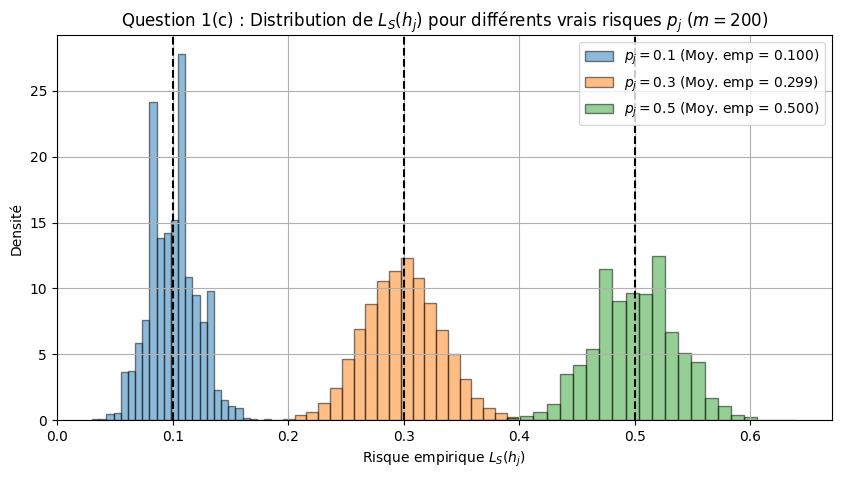

In [3]:
np.random.seed(42)   

true_risks = [0.1, 0.3, 0.5]
sample_sizes = [10, 50, 200, 1000]
n_simulations = 10000
p_fixed = 0.3

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()
print(f"=== Question 1(d) : Comparaison Moyenne Empirique vs Vrai Risque (p_j = {p_fixed}) ===")

for i, m in enumerate(sample_sizes):
    # Question 1 (a) 
    E_j = np.random.binomial(n=m, p=p_fixed, size=n_simulations)

    # Question 1 (b) 
    L_S = E_j / m

    # Question 1 (d)
    emp_mean = np.mean(L_S)
    emp_std = np.std(L_S)
    theo_std = np.sqrt(p_fixed * (1 - p_fixed) / m)
    print(f"Taille m = {m:4d} | Moyenne empirique de L_S = {emp_mean:.4f} | Vrai risque p_j = {p_fixed:.4f} | "
          f"Écart-type emp. = {emp_std:.4f} (Théo = {theo_std:.4f})")

    # Question 1 (c) 
    bins = np.arange(-0.5, m + 1.5) / m if m <= 50 else 25
    axes[i].hist(L_S, bins=bins, density=True, alpha=0.7, color='steelblue', edgecolor='black')
    axes[i].axvline(p_fixed, color='red', linestyle='--', linewidth=2, label=f'Vrai risque $L_D(h_j) = {p_fixed}$')
    axes[i].axvline(emp_mean, color='orange', linestyle=':', linewidth=2, label=f'Moyenne emp. ({emp_mean:.3f})')
    axes[i].set_title(f"Question 1(c) : Distribution de $L_S(h_j)$ pour $m = {m}$")
    axes[i].set_xlabel("Risque empirique $L_S(h_j)$")
    axes[i].set_ylabel("Densité")
    axes[i].legend()

plt.suptitle(f"Question 1 : Concentration de $L_S(h_j)$ autour de $L_D(h_j) = {p_fixed}$ quand $m$ augmente", fontsize=14)
plt.tight_layout()
plt.show()
m_fixed = 200
plt.figure(figsize=(10, 5))
print(f"\n=== Question 1(d) : Vérification pour plusieurs risques p_1, ..., p_K (m = {m_fixed}) ===")

for p_j in true_risks:
    # Question 1 (a)
    E_j = np.random.binomial(n=m_fixed, p=p_j, size=n_simulations)

    # Question 1 (b) 
    L_S = E_j / m_fixed

    # Question 1 (d)
    emp_mean = np.mean(L_S)
    theo_std = np.sqrt(p_j * (1 - p_j) / m_fixed)
    print(f"Vrai risque p_j = {p_j:.2f} | Moyenne empirique = {emp_mean:.4f} | "
          f"Écart-type emp. = {np.std(L_S):.4f} (Théo = {theo_std:.4f})")

    # Question 1 (c)
    plt.hist(L_S, bins=25, density=True, alpha=0.5, edgecolor='black', label=f"$p_j = {p_j}$ (Moy. emp = {emp_mean:.3f})")
    plt.axvline(p_j, color='black', linestyle='--')

plt.title(f"Question 1(c) : Distribution de $L_S(h_j)$ pour différents vrais risques $p_j$ ($m = {m_fixed}$)")
plt.xlabel("Risque empirique $L_S(h_j)$")
plt.ylabel("Densité")
plt.legend()
plt.show()

**Ce que j' observe.**

*La moyenne.* La moyenne empirique de $L_S$ est égale au vrai risque dès le plus petit échantillon : 0,2972 pour $m = 10$, puis 0,3011, 0,3000 et 0,3000. Pour $m = 200$ et les trois risques testés on trouve 0,1001 ; 0,2990 ; 0,5003. Ce n'est pas un hasard : $\mathbb{E}[E_j/m] = m p_j / m = p_j$, donc $L_S(h_j)$ est un estimateur **sans biais** de $L_D(h_j)$, quelle que soit la taille de l'échantillon.

*La dispersion.* C'est elle qui change avec $m$. L'écart-type passe de 0,143 ($m = 10$) à 0,065, 0,032 puis 0,014 ($m = 1000$), ce qui colle aux valeurs théoriques (0,145 ; 0,065 ; 0,032 ; 0,0145). Multiplier $m$ par 100 divise l'écart-type par 10 : la décroissance se fait en $1/\sqrt{m}$. Les histogrammes le montrent bien (les quatre ont le même axe des abscisses) : à $m = 10$ la distribution est discrète, étalée et asymétrique, tandis qu'à $m = 1000$ on voit une bosse étroite d'allure gaussienne centrée sur 0,3, ce qui est le théorème central limite à l'œuvre.

*Pourquoi les petits échantillons sont dangereux.* À $m = 10$, la probabilité d'obtenir $L_S = 0$ est de $0{,}7^{10} \approx 3\,\%$ : environ une fois sur trente, une hypothèse qui se trompe 30 % du temps a l'air parfaite sur l'échantillon. À $m = 1000$ cela n'arrive plus jamais en pratique.

*Rôle de $p_j$.* À $m$ fixé, la dispersion dépend aussi du risque : 0,021 pour $p = 0{,}1$, 0,033 pour $p = 0{,}3$, 0,036 pour $p = 0{,}5$. La variance $p(1-p)$ est maximale en 0,5, c'est donc le pire cas pour l'estimation. Je m'en resservirai pour expliquer pourquoi la borne de Hoeffding est pessimiste : elle majore tout par ce pire cas.

### Question 2 – Écart entre risque empirique et vrai risque

Je fixe $p_j = 0{,}3$ et $\varepsilon = 0{,}05$, et pour chaque $m$ entre 50 et 1500 j'estime $\Pr[|L_S(h_j) - L_D(h_j)| > \varepsilon]$ sur 10 000 échantillons. Je compare à la borne de Hoeffding $2e^{-2m\varepsilon^2}$.

   m | empirique | Hoeffding | rapport entre Hoeffding/empirique
  50 |  0.4376   |  1.0000   |      2.3
 100 |  0.2308   |  1.0000   |      4.3
 200 |  0.0958   |  0.7358   |      7.7
 300 |  0.0529   |  0.4463   |      8.4
 400 |  0.0240   |  0.2707   |     11.3
 500 |  0.0114   |  0.1642   |     14.4
 700 |  0.0032   |  0.0604   |     18.9


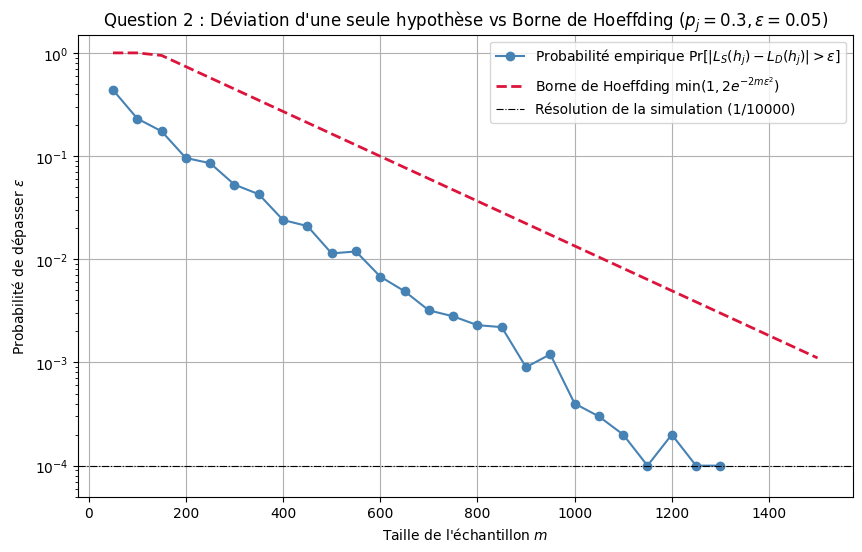

In [9]:
# Question 2
np.random.seed(1)
p_j = 0.3
epsilon = 0.05
m_values = np.arange(50, 1501, 50)
n_simulations = 10000

emp_probs_q2 = []
hoeffding_bounds_q2 = []

for m in m_values:
    E_j = np.random.binomial(n=m, p=p_j, size=n_simulations)
    L_S = E_j / m

    # Question 2 (a) 
    deviations = np.abs(L_S - p_j)

    # Question 2 (b) 
    prob_exceed = np.mean(deviations > epsilon)
    emp_probs_q2.append(prob_exceed)

    # Question 2 (c) 
    bound = 2 * np.exp(-2 * m * (epsilon ** 2))
    hoeffding_bounds_q2.append(min(1.0, bound)) 

emp_probs_q2 = np.array(emp_probs_q2)
hoeffding_bounds_q2 = np.array(hoeffding_bounds_q2)

print("   m | empirique | Hoeffding | rapport entre Hoeffding/empirique")
for m, e, h in zip(m_values, emp_probs_q2, hoeffding_bounds_q2):
    if m in (50, 100, 200, 300, 400, 500, 700):
        ratio = f"{h / e:8.1f}" if e > 0 else "    inf"
        print(f"{m:4d} |  {e:.4f}   |  {h:.4f}   | {ratio}")

# Question 2 (d) 
emp_plot = np.where(emp_probs_q2 > 0, emp_probs_q2, np.nan)
plt.figure(figsize=(10, 6))
plt.plot(m_values, emp_plot, 'o-', color='steelblue', label=r"Probabilité empirique $\Pr[|L_S(h_j) - L_D(h_j)| > \epsilon]$")
plt.plot(m_values, hoeffding_bounds_q2, '--', color='crimson', linewidth=2, label=r"Borne de Hoeffding $\min(1, 2e^{-2m\epsilon^2})$")
plt.axhline(1 / n_simulations, color='black', linewidth=0.8, linestyle='-.', label="Résolution de la simulation (1/10000)")
plt.title(rf"Question 2 : Déviation d'une seule hypothèse vs Borne de Hoeffding ($p_j={p_j}, \epsilon={epsilon}$)")
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel(r"Probabilité de dépasser $\epsilon$")
plt.yscale('log')
plt.ylim(5e-5, 1.5)
plt.legend()
plt.show()

On observe que la probabilité de dépasser $\varepsilon$ décroît à peu près en ligne droite , exactement comme la borne de Hoeffding. Mais la borne reste au-dessus de la simulation partout :

| $m$ | probabilité empirique | borne de Hoeffding | borne / empirique |
|---|---|---|---|
| 50 | 0,438 | 1 (plafonnée) | 2,3 |
| 200 | 0,096 | 0,736 | 7,7 |
| 500 | 0,011 | 0,164 | 14 |
| 700 | 0,003 | 0,060 | 19 |

La borne est valide mais pas exacte. Elle n'est jamais violée, ce qui est son rôle, mais elle surestime la vraie probabilité d'un facteur qui grandit avec $m$. Tant que $m \le \ln 2/0{,}005 \approx 138$ elle dépasse même 1, donc elle est complètement vide (et elle reste très proche de 1 jusqu'à $m = 150$), alors que la vraie probabilité est de 0,44 à $m = 50$ et de 0,23 à $m = 100$.Deux raisons expliquent le décalage. D'abord Hoeffding ne dépend que de $\varepsilon$ et pas de $p_j$ : il suppose le pire cas $p(1-p) = 1/4$, alors qu'ici $p(1-p) = 0{,}21$. Ensuite, la borne utilise une majoration uniforme qui conduit à un taux de décroissance plus prudent que celui observé empiriquement. C'est pourquoi le rapport entre la borne et les résultats de la simulation s'élargit au lieu de rester constant (le petit écart restant venant surtout de ce que $L_S$ ne prend que des valeurs multiples de $1/m$ et que l'inégalité est stricte).Il faut retenir que la borne a la bonne forme (exponentielle en $m$ et en $\varepsilon^2$) et elle est valable sans rien savoir de la loi, quel que soit $m$. Le prix à payer, ce sont des constantes pessimistes. Remarque de lecture : au-delà de $m \approx 1150$ les points empiriques touchent la résolution de la simulation ($1/10\,000$) et fluctuent, il ne faut pas les interpréter.

### Question 3 – D'une hypothèse à la convergence uniforme

   m | Pr[Delta_S > eps] empirique | borne union (K=20) | borne Hoeffding 
  50 |          1.0000             |       1.0000       |       1.0000 |
 125 |          0.9900             |       1.0000       |       1.0000 |
 200 |          0.9014             |       1.0000       |       0.7358 |
 350 |          0.5322             |       1.0000       |       0.3475 |
 500 |          0.2540             |       1.0000       |       0.1642 |
 650 |          0.1040             |       1.0000       |       0.0775 |
 800 |          0.0362             |       0.7326       |       0.0366 |
1100 |          0.0116             |       0.1635       |       0.0082 |


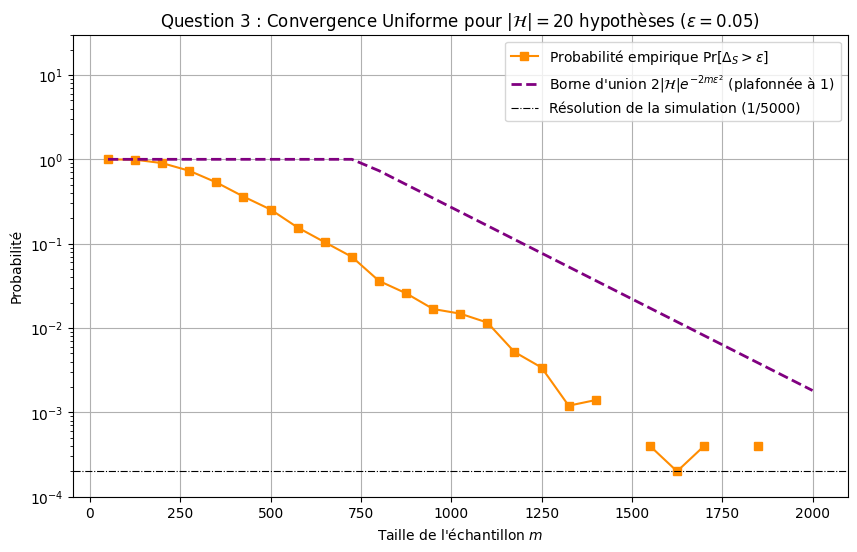

In [12]:
# Question 3
np.random.seed(2)
K = 20
true_risks_H = np.linspace(0.1, 0.5, K)  
epsilon = 0.05
m_values_q3 = np.arange(50, 2001, 75)
n_simulations = 5000

emp_probs_q3 = []
uniform_bounds_q3 = []

for m in m_values_q3:
    # Question 3 (a) 
    E_matrix = np.random.binomial(n=m, p=true_risks_H, size=(n_simulations, K))
    L_S_matrix = E_matrix / m

    # Question 3 (b) 
    Delta_S = np.max(np.abs(L_S_matrix - true_risks_H), axis=1)

    # Question 3 (c) 
    prob_uniform_exceed = np.mean(Delta_S > epsilon)
    emp_probs_q3.append(prob_uniform_exceed)

    # Question 3 (d) 
    u_bound = 2 * K * np.exp(-2 * m * (epsilon ** 2))
    uniform_bounds_q3.append(min(1.0, u_bound))

emp_probs_q3 = np.array(emp_probs_q3)
uniform_bounds_q3 = np.array(uniform_bounds_q3)
single_bound = np.minimum(1.0, 2 * np.exp(-2 * m_values_q3 * epsilon ** 2))

print("   m | Pr[Delta_S > eps] empirique | borne union (K=20) | borne Hoeffding ")
for m, e, u, s in zip(m_values_q3, emp_probs_q3, uniform_bounds_q3, single_bound):
    if m in (50, 125, 200, 350, 500, 650, 800, 1100):
        print(f"{m:4d} |          {e:.4f}             |       {u:.4f}       |       {s:.4f} |")

# Question 3 (e)
emp_plot = np.where(emp_probs_q3 > 0, emp_probs_q3, np.nan)
plt.figure(figsize=(10, 6))
plt.plot(m_values_q3, emp_plot, 's-', color='darkorange', label=r"Probabilité empirique $\Pr[\Delta_S > \epsilon]$")
plt.plot(m_values_q3, uniform_bounds_q3, '--', color='purple', linewidth=2, label=r"Borne d'union $2|\mathcal{H}|e^{-2m\epsilon^2}$ (plafonnée à 1)")
plt.axhline(1 / n_simulations, color='black', linewidth=0.8, linestyle='-.', label="Résolution de la simulation (1/5000)")
plt.yscale('log')
plt.ylim(1e-4, 30)
plt.title(rf"Question 3 : Convergence Uniforme pour $|\mathcal{{H}}| = {K}$ hypothèses ($\epsilon = {epsilon}$)")
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel("Probabilité")
plt.legend()
plt.show()

**Ce qu'on observe.** La probabilité que *au moins une* hypothèse soit mal estimée reste élevée beaucoup plus longtemps que pour une hypothèse seule :

| $m$ | $\Pr[\Delta_S > \varepsilon]$ (20 hypothèses) | une seule hypothèse ($p = 0{,}3$, Q2) |
|---|---|---|
| 200 | 0,90 | 0,096 |
| 500 | 0,25 | 0,011 |
| 800 | 0,036 | environ 0,002 |

À $m = 200$ la quasi-totalité des échantillons contient au moins une hypothèse dont le risque empirique est à plus de 5 points de la vérité, alors qu'une hypothèse prise seule n'a qu'une chance sur dix de l'être. C'est exactement l'idée de la convergence **uniforme** : il ne suffit pas que chaque $L_S(h)$ soit bon séparément, il faut que *tous* le soient simultanément, et le maximum de $K$ quantités aléatoires est typiquement plus grand que chacune d'elles. C'est aussi ce qui compte pour l'ERM, puisque l'algorithme choisit l'hypothèse qui a l'air la meilleure, c'est-à-dire potentiellement celle qui a eu de la chance sur l'échantillon.

**La borne de l'union.** Elle vaut 1 tant que $m < \ln(40)/0{,}005 \approx 738$, donc elle ne dit rien sur toute la zone où la probabilité empirique passe de 1 à environ 0,1. À $m = 800$ elle donne 0,73 contre 0,036 observé, et à $m = 1100$ elle donne 0,16 contre 0,012. Elle est donc valide mais pessimiste d'un facteur 15 à 20 dans la zone utile.

Je vois deux causes. La première est celle de la Q2 : Hoeffding surestime chaque terme, surtout pour les hypothèses de risque éloigné de 0,5. La seconde est propre à l'union : sommer les 20 probabilités revient à traiter les hypothèses de faible variance (celles proches de $p = 0{,}1$) comme si elles étaient aussi dangereuses que celles proches de 0,5, alors qu'en pratique ce sont surtout ces dernières qui font dépasser $\varepsilon$. On remarque d'ailleurs que la courbe empirique est à peu près au niveau de la borne de Hoeffding pour *une seule* hypothèse (0,036 contre 0,037 à $m = 800$). Je ne vois pas cela comme un résultat théorique, plutôt comme un ordre de grandeur : ici, les 20 hypothèses ne coûtent pas le facteur 20 que prévoit l'union.

### Questions 4 et 5 – Taille de la classe et complexité d'échantillon expérimentale

**Question 4.** Je refais l'expérience de la Question 3 avec $\varepsilon = 0{,}05$ fixé pour $|\mathcal{H}| \in \{5, 10, 50, 100, 500\}$. Pour chaque taille, les risques vrais sont tirés uniformément dans $[0{,}1 ; 0{,}5]$, et je trace $\Pr[\Delta_S > \varepsilon]$ en fonction de $m$.

**Question 5.** Avec $\delta = 0{,}1$, je cherche pour chaque classe le plus petit $m$ testé tel que $\Pr[\Delta_S > \varepsilon] \le \delta$ et je le compare à la taille suffisante donnée par la théorie,
$$m \ge \frac{\ln(2|\mathcal{H}|/\delta)}{2\varepsilon^2}.$$
Pour ne pas rester sur un seul cas, je refais la même chose avec un second niveau de précision, $\varepsilon = 0{,}10$ (grille de $m$ plus fine, de 10 en 10). Le cas $|\mathcal{H}| = 100$, $\varepsilon = 0{,}05$, $\delta = 0{,}1$ est celui de la ligne centrale du tableau.

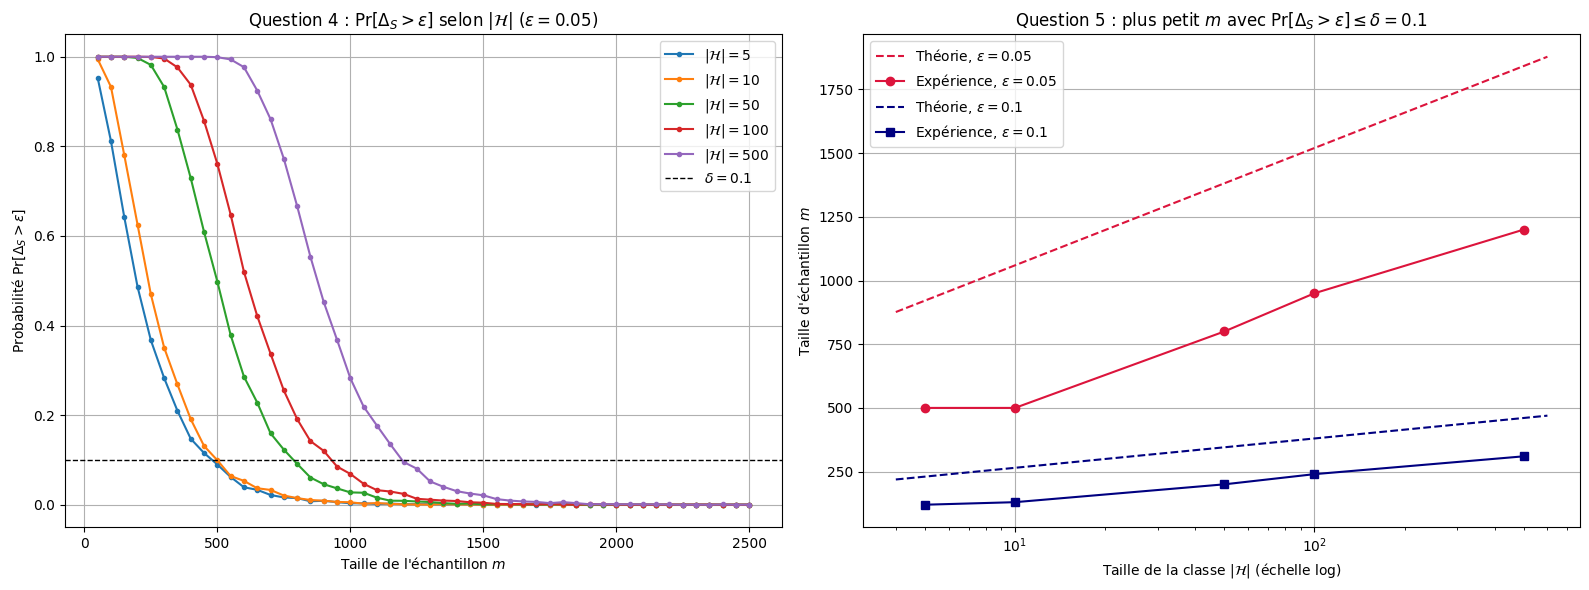

Question 4 : Pr[Delta_S > epsilon] estimée (epsilon = 0.05)
   |H|  | m=500  | m=1000 | m=1500
     5  | 0.090  | 0.003  | 0.000
    10  | 0.099  | 0.005  | 0.000
    50  | 0.498  | 0.028  | 0.001
   100  | 0.761  | 0.069  | 0.004
   500  | 0.999  | 0.282  | 0.021

Question 5 (delta = 0.1) : m minimal testé vs m théorique suffisant

  epsilon = 0.05   (pas de la grille de m : 50)
   |H|  | m expérimental | m théorique | rapport théorique/expérimental
     5  |        500     |     921.0   |       1.84
    10  |        500     |    1059.7   |       2.12
    50  |        800     |    1381.6   |       1.73
   100  |        950     |    1520.2   |       1.60
   500  |       1200     |    1842.1   |       1.54

  epsilon = 0.1   (pas de la grille de m : 10)
   |H|  | m expérimental | m théorique | rapport théorique/expérimental
     5  |        120     |     230.3   |       1.92
    10  |        130     |     264.9   |       2.04
    50  |        200     |     345.4   |       1.73
   100  |

In [13]:
# Questions 4 et 5
np.random.seed(3)

def prob_uniform_deviation(K, eps, m_grid, n_sim, risks):
    """Estime Pr[Delta_S > eps] pour une classe de K hypothèses de risques vrais `risks`,
    pour chaque taille d'échantillon de m_grid (même simulation que la Question 3)."""
    probs = []
    for m in m_grid:
        E = np.random.binomial(n=m, p=risks, size=(n_sim, K))
        Delta = np.max(np.abs(E / m - risks), axis=1)
        probs.append(np.mean(Delta > eps))
    return np.array(probs)

H_sizes = [5, 10, 50, 100, 500]
delta = 0.1

# --- Question 4 : epsilon = 0.05 ---
epsilon = 0.05
m_values_q4 = np.arange(50, 2501, 50)
n_sim_q4 = 4000

risks_by_H = {H: np.random.uniform(0.1, 0.5, H) for H in H_sizes}
results_q4 = {H: prob_uniform_deviation(H, epsilon, m_values_q4, n_sim_q4, risks_by_H[H]) for H in H_sizes}

# --- Question 5 : même chose avec un second epsilon, pour varier les situations ---
epsilon_b = 0.10
m_values_q5b = np.arange(10, 801, 10)
results_q5b = {H: prob_uniform_deviation(H, epsilon_b, m_values_q5b, n_sim_q4, risks_by_H[H]) for H in H_sizes}

def smallest_m(m_grid, probs, delta):
    """Plus petit m testé tel que Pr[Delta_S > eps] <= delta (None si jamais atteint)."""
    ok = np.where(probs <= delta)[0]
    return int(m_grid[ok[0]]) if len(ok) > 0 else None

def m_theory(H, eps, delta):
    """Taille d'échantillon suffisante : m >= log(2|H|/delta) / (2 eps^2)."""
    return np.log(2 * H / delta) / (2 * eps ** 2)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for H in H_sizes:
    ax1.plot(m_values_q4, results_q4[H], 'o-', markersize=3, label=rf"$|\mathcal{{H}}| = {H}$")
ax1.axhline(delta, color='black', linestyle='--', linewidth=1, label=rf"$\delta = {delta}$")
ax1.set_title(rf"Question 4 : $\Pr[\Delta_S > \epsilon]$ selon $|\mathcal{{H}}|$ ($\epsilon = {epsilon}$)")
ax1.set_xlabel("Taille de l'échantillon $m$")
ax1.set_ylabel(r"Probabilité $\Pr[\Delta_S > \epsilon]$")
ax1.legend()

# Question 5 : m expérimental vs m théorique en fonction de |H|
Hs_fine = np.logspace(np.log10(4), np.log10(600), 100)
exp_a = [smallest_m(m_values_q4, results_q4[H], delta) for H in H_sizes]
exp_b = [smallest_m(m_values_q5b, results_q5b[H], delta) for H in H_sizes]
ax2.plot(Hs_fine, m_theory(Hs_fine, epsilon, delta), '--', color='crimson', label=rf"Théorie, $\epsilon={epsilon}$")
ax2.plot(H_sizes, exp_a, 'o-', color='crimson', label=rf"Expérience, $\epsilon={epsilon}$")
ax2.plot(Hs_fine, m_theory(Hs_fine, epsilon_b, delta), '--', color='navy', label=rf"Théorie, $\epsilon={epsilon_b}$")
ax2.plot(H_sizes, exp_b, 's-', color='navy', label=rf"Expérience, $\epsilon={epsilon_b}$")
ax2.set_xscale('log')
ax2.set_title(rf"Question 5 : plus petit $m$ avec $\Pr[\Delta_S > \epsilon] \leq \delta = {delta}$")
ax2.set_xlabel(r"Taille de la classe $|\mathcal{H}|$ (échelle log)")
ax2.set_ylabel("Taille d'échantillon $m$")
ax2.legend()
plt.tight_layout()
plt.show()

# ---------- valeurs Question 4 ----------
print(f"Question 4 : Pr[Delta_S > epsilon] estimée (epsilon = {epsilon})")
print("   |H|  | m=500  | m=1000 | m=1500")
for H in H_sizes:
    vals = [results_q4[H][np.where(m_values_q4 == mm)[0][0]] for mm in (500, 1000, 1500)]
    print(f"  {H:4d}  | {vals[0]:.3f}  | {vals[1]:.3f}  | {vals[2]:.3f}")
print()

# ---------- Tableau récapitulatif de la Question 5 ----------
print(f"Question 5 (delta = {delta}) : m minimal testé vs m théorique suffisant")
for eps, grid, exp_list in [(epsilon, m_values_q4, exp_a), (epsilon_b, m_values_q5b, exp_b)]:
    print(f"\n  epsilon = {eps}   (pas de la grille de m : {grid[1] - grid[0]})")
    print("   |H|  | m expérimental | m théorique | rapport théorique/expérimental")
    for H, me in zip(H_sizes, exp_list):
        mt = m_theory(H, eps, delta)
        r = f"{mt / me:5.2f}" if me else "  -"
        print(f"  {H:4d}  |      {str(me):>5s}     |   {mt:7.1f}   |      {r}")

lnH = np.log(H_sizes)
slope_a = np.polyfit(lnH, exp_a, 1)[0]
slope_b = np.polyfit(lnH, exp_b, 1)[0]
print(f"\nPente expérimentale de m en fonction de ln|H| : {slope_a:.0f} (eps=0.05) et {slope_b:.0f} (eps=0.10)")
print(f"Pente théorique 1/(2 eps^2)                  : {1/(2*epsilon**2):.0f} (eps=0.05) et {1/(2*epsilon_b**2):.0f} (eps=0.10)")

### Discussion de la Question 4

**Comment $|\mathcal{H}|$ affecte la convergence uniforme.** Toutes les courbes ont la même allure (elles tombent de 1 vers 0), mais plus la classe est grande, plus elles sont décalées vers la droite. À $m = 500$ on lit :

| $\lvert\mathcal{H}\rvert$ | 5 | 10 | 50 | 100 | 500 |
|---|---|---|---|---|---|
| $\Pr[\Delta_S > \varepsilon]$ à $m = 500$ | 0,09 | 0,10 | 0,50 | 0,76 | 0,999 |
| à $m = 1000$ | 0,003 | 0,005 | 0,028 | 0,069 | 0,282 |
| à $m = 1500$ | 0,000 | 0,000 | 0,001 | 0,004 | 0,021 |

Avec plus d'hypothèses il y a plus de chances qu'au moins l'une d'elles s'écarte de son vrai risque, donc $\Delta_S$ est stochastiquement plus grand. Pour 500 hypothèses, 500 exemples ne suffisent pas du tout (le maximum dépasse $\varepsilon$ presque à chaque fois), alors que pour 5 hypothèses on est déjà à environ 9 %.

**Une classe plus grande demande-t-elle plus de données ?** Oui, dans le sens où, pour atteindre $\delta = 0{,}1$, il faut environ 500 exemples pour 5 ou 10 hypothèses, 800 pour 50, 950 pour 100 et 1200 pour 500 (voir le tableau de la Question 5). Mais la croissance est lente : multiplier la taille de la classe par 100 (de 5 à 500) ne fait qu'un peu plus que doubler le $m$ nécessaire (facteur 2,4), pas le multiplier par 100.

**Lien avec le $\log|\mathcal{H}|$.** C'est exactement ce que prédit la formule de complexité d'échantillon : $m \gtrsim \big(\ln(2/\delta) + \ln|\mathcal{H}|\big)/(2\varepsilon^2)$ est *linéaire en $\ln|\mathcal{H}|$*. Concrètement, avec $\varepsilon = 0{,}05$, doubler la classe coûte un supplément constant d'environ $\ln 2/(2\varepsilon^2) \approx 139$ exemples, et la multiplier par 10 en coûte environ 460, quelle que soit la taille de départ. Sur le graphique de droite, les points expérimentaux sont bien alignés sur une droite en échelle log-x. Les pentes mesurées sont de 162 (pour $\varepsilon = 0{,}05$) et 43 (pour $\varepsilon = 0{,}10$), à comparer aux pentes théoriques 200 et 50. Elles sont un peu plus petites (donc la théorie est pessimiste) mais du bon ordre de grandeur et surtout avec le bon comportement. C'est cette dépendance en logarithme qui rend raisonnables des classes énormes : une classe de $2^d$ hypothèses, par exemple décrite par $d$ bits, n'a besoin que de $m$ proportionnel à $d$.

### Discussion de la Question 5

| $\varepsilon$ | $\lvert\mathcal{H}\rvert$ | $m$ expérimental | $m$ théorique | théorique / expérimental |
|---|---|---|---|---|
| 0,05 | 5 | 500 | 921 | 1,84 |
| 0,05 | 10 | 500 | 1060 | 2,12 |
| 0,05 | 50 | 800 | 1382 | 1,73 |
| 0,05 | **100** | **950** | **1520** | **1,60** |
| 0,05 | 500 | 1200 | 1842 | 1,54 |
| 0,10 | 100 | 240 | 380 | 1,58 |

Sur tous les cas testés (les deux $\varepsilon$ et les cinq tailles, voir le tableau complet dans la sortie), la valeur théorique est entre 1,5 et 2,1 fois plus grande que la valeur expérimentale. Pour le cas demandé ($|\mathcal{H}| = 100$, $\varepsilon = 0{,}05$, $\delta = 0{,}1$), 950 exemples suffisent en simulation alors que la théorie en garantit 1520. La théorie n'est donc jamais prise en défaut, et elle n'est pas loin : un facteur 1,6 sur la complexité d'échantillon est plutôt un bon résultat pour une borne qui ne suppose rien sur la loi.

**Pourquoi il faut lire la formule comme une condition suffisante et non comme le minimum exact.**

1. Elle est conçue pour le *pire cas* : n'importe quelle distribution, n'importe quels risques, y compris tous égaux à 0,5 (variance maximale). Dans mon expérience les risques sont répartis entre 0,1 et 0,5, la plupart des hypothèses ont une variance plus faible et sont donc plus faciles à estimer.
2. Hoeffding n'utilise pas la variance (on l'a vu en Q2), et la borne de l'union additionne les probabilités sans tenir compte du fait que les événements ne sont pas tous aussi probables (Q3). Chacune de ces deux étapes perd un peu.
3. On compare une borne à une probabilité exacte : « borne $\le \delta$ » est plus exigeant que « probabilité $\le \delta$ ».
4. Dans de vraies classes d'hypothèses, les erreurs sont corrélées (deux seuils voisins se trompent presque sur les mêmes points), donc le nombre « effectif » d'hypothèses est bien plus petit que $|\mathcal{H}|$. La borne, elle, ignore cela.

Deux réserves sur la précision des mesures : la grille de $m$ a un pas de 50 (de 10 pour $\varepsilon = 0{,}10$), donc les valeurs expérimentales sont connues à ce pas près (c'est ce qui explique que $|\mathcal{H}| = 5$ et $10$ donnent tous les deux 500), et l'estimation de la probabilité fluctue d'environ $\pm 0{,}005$ autour de $\delta$. Ces imprécisions déplacent le $m$ trouvé de quelques dizaines d'exemples au plus, bien moins que l'écart avec la théorie (de 400 à 650 exemples pour $\varepsilon = 0{,}05$). Le facteur 1,5 à 2 est donc bien réel et pas un artefact.

---
## Partie II – Simuler le No-Free-Lunch

On travaille sur un domaine fini $\mathcal{X} = \{1, \dots, N\}$ muni de la loi uniforme. À chaque répétition, on tire une **nouvelle cible** $f : \mathcal{X} \to \{0,1\}$ en lançant une pièce équilibrée pour chaque $x$, puis un échantillon $S$ de $m$ points tirés uniformément avec remise. L'algorithme $A$ mémorise : sur un point vu il renvoie l'étiquette observée, sur un point jamais vu il prédit 0.

### Un peu de théorie avant de simuler

**Question 6.** Un point $x$ fixé n'est pas tiré à un tirage donné avec probabilité $1 - 1/N$, et les $m$ tirages sont indépendants, donc $\Pr[x \text{ non vu}] = (1 - 1/N)^m$. La fraction de points non vus est $\frac{1}{N}\sum_x \mathbf{1}[x \text{ non vu}]$. Par linéarité de l'espérance (qui n'a pas besoin que les événements « $x$ non vu » soient indépendants entre eux, et ils ne le sont pas), son espérance vaut $\frac{1}{N} \cdot N \cdot (1-1/N)^m = (1-1/N)^m$. C'est donc aussi la probabilité d'un point fixé.

**Question 7.** Regardons l'erreur de $A(S)$ en un point $x$.
- Si $x$ est vu, $A(S)(x)$ est l'étiquette observée, et comme $f$ est une vraie fonction (sans bruit), c'est $f(x)$ : pas d'erreur.
- Si $x$ n'est pas vu, la prédiction est 0, tandis que $f(x) \sim \text{Bernoulli}(1/2)$ est indépendante de l'échantillon (qui ne contient aucune information sur $f(x)$). L'erreur se produit si $f(x) = 1$, donc avec probabilité $1/2$.

D'où $\mathbb{E}\big[\mathbf{1}[A(S)(x) \ne f(x)]\big] = \Pr[x \text{ non vu}] \cdot \tfrac12 + \Pr[x \text{ vu}] \cdot 0 = \tfrac12 (1-1/N)^m$, et comme $L_D(A(S))$ est la moyenne de ces indicateurs sur $x$, on obtient
$$\mathbb{E}[L_D(A(S))] = \frac12\Big(1 - \frac1N\Big)^m.$$

**Question 8.** Je teste en plus deux autres règles pour les points non vus : toujours prédire 1, et prédire un Bernoulli(1/2). Le calcul ci-dessus ne dépend pas de la règle (il suffit que la prédiction soit indépendante de $f(x)$), donc la même formule devrait valoir pour les trois.

=== Partie II : Calculs No-Free-Lunch en cours ===


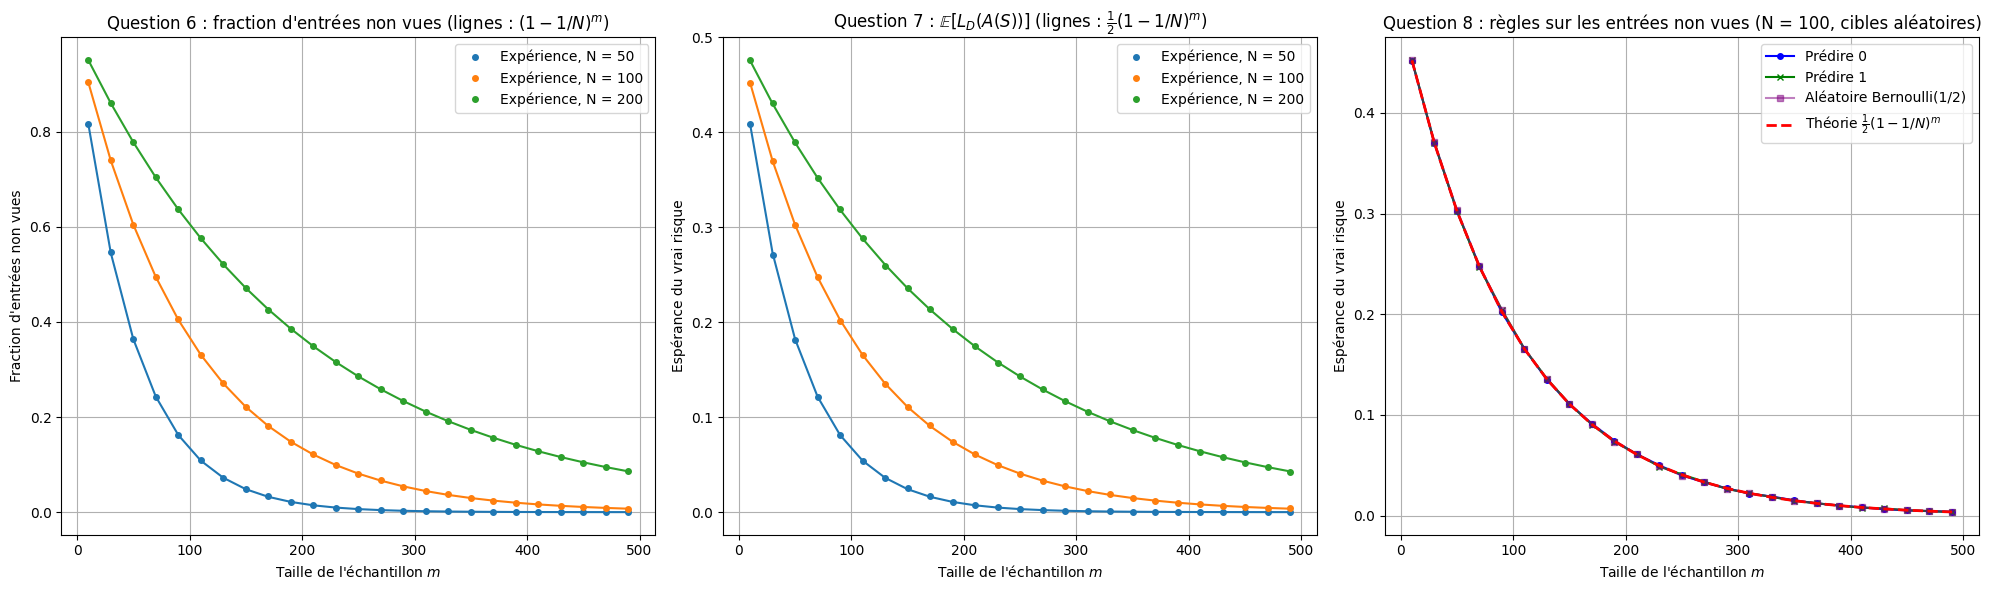

Écart maximal |expérience - théorie| sur toute la grille de m :
  N =  50 : fraction non vue 0.0017 | risque (prédire 0) 0.0019
  N = 100 : fraction non vue 0.0012 | risque (prédire 0) 0.0008
  N = 200 : fraction non vue 0.0006 | risque (prédire 0) 0.0014

N = 100, m = 50 : fraction non vue = 0.605 (théorie 0.605)
   risque prédire 0 = 0.302 | prédire 1 = 0.303 | aléatoire = 0.304 | théorie = 0.303


In [15]:
# Partie II : No-Free-Lunch
np.random.seed(4)

N_list = [50, 100, 200]                 
m_values_nfl = np.arange(10, 501, 20)   
n_simulations = 2000                    

res = {}   

print("=== Partie II : Calculs No-Free-Lunch en cours ===")

for N in N_list:
    exp_frac_unseen, exp_risk_pred_0, exp_risk_pred_1, exp_risk_pred_rand = [], [], [], []

    for m in m_values_nfl:
        frac_unseen_list, risk_0_list, risk_1_list, risk_rand_list = [], [], [], []

        for _ in range(n_simulations):
            # Question 6 (a) 
            f_target = np.random.binomial(n=1, p=0.5, size=N)

            # Question 6 (b) 
            S_indices = np.random.randint(0, N, size=m)
            seen_indices = np.unique(S_indices)
            num_unseen = N - len(seen_indices)

            # Question 6 (c) 
            frac_unseen_list.append(num_unseen / N)
            pred_0 = np.zeros(N)
            pred_0[seen_indices] = f_target[seen_indices]

            pred_1 = np.ones(N)
            pred_1[seen_indices] = f_target[seen_indices]

            pred_rand = np.random.binomial(n=1, p=0.5, size=N)
            pred_rand[seen_indices] = f_target[seen_indices]

            # Question 7 
            risk_0_list.append(np.mean(pred_0 != f_target))
            risk_1_list.append(np.mean(pred_1 != f_target))
            risk_rand_list.append(np.mean(pred_rand != f_target))

        exp_frac_unseen.append(np.mean(frac_unseen_list))
        exp_risk_pred_0.append(np.mean(risk_0_list))
        exp_risk_pred_1.append(np.mean(risk_1_list))
        exp_risk_pred_rand.append(np.mean(risk_rand_list))

    res[N] = dict(frac=np.array(exp_frac_unseen), r0=np.array(exp_risk_pred_0),
                  r1=np.array(exp_risk_pred_1), rr=np.array(exp_risk_pred_rand))
colors = {50: 'tab:blue', 100: 'tab:orange', 200: 'tab:green'}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# Question 6 : fraction de points non vus
for N in N_list:
    ax1.plot(m_values_nfl, res[N]['frac'], 'o', color=colors[N], markersize=4, label=f"Expérience, N = {N}")
    ax1.plot(m_values_nfl, (1 - 1 / N) ** m_values_nfl, '-', color=colors[N], linewidth=1.5)
ax1.set_title(r"Question 6 : fraction d'entrées non vues (lignes : $(1-1/N)^m$)")
ax1.set_xlabel("Taille de l'échantillon $m$")
ax1.set_ylabel("Fraction d'entrées non vues")
ax1.legend()

# Question 7 : risque de l'algorithme  vs théorie
for N in N_list:
    ax2.plot(m_values_nfl, res[N]['r0'], 'o', color=colors[N], markersize=4, label=f"Expérience, N = {N}")
    ax2.plot(m_values_nfl, 0.5 * (1 - 1 / N) ** m_values_nfl, '-', color=colors[N], linewidth=1.5)
ax2.set_title(r"Question 7 : $\mathbb{E}[L_D(A(S))]$ (lignes : $\frac{1}{2}(1-1/N)^m$)")
ax2.set_xlabel("Taille de l'échantillon $m$")
ax2.set_ylabel(r"Espérance du vrai risque")
ax2.legend()

# Question 8 
N = 100
ax3.plot(m_values_nfl, res[N]['r0'], 'o-', color='blue', markersize=4, label="Prédire 0")
ax3.plot(m_values_nfl, res[N]['r1'], 'x-', color='green', markersize=5, label="Prédire 1")
ax3.plot(m_values_nfl, res[N]['rr'], 's-', color='purple', markersize=4, alpha=0.5, label="Aléatoire Bernoulli(1/2)")
ax3.plot(m_values_nfl, 0.5 * (1 - 1 / N) ** m_values_nfl, '--', color='red', linewidth=2, label=r"Théorie $\frac{1}{2}(1-1/N)^m$")
ax3.set_title("Question 8 : règles sur les entrées non vues (N = 100, cibles aléatoires)")
ax3.set_xlabel("Taille de l'échantillon $m$")
ax3.set_ylabel(r"Espérance du vrai risque")
ax3.legend()

plt.tight_layout()
plt.show()

print("Écart maximal |expérience - théorie| sur toute la grille de m :")
for N in N_list:
    d_frac = np.max(np.abs(res[N]['frac'] - (1 - 1 / N) ** m_values_nfl))
    d_risk = np.max(np.abs(res[N]['r0'] - 0.5 * (1 - 1 / N) ** m_values_nfl))
    print(f"  N = {N:3d} : fraction non vue {d_frac:.4f} | risque (prédire 0) {d_risk:.4f}")

i = np.where(m_values_nfl == 50)[0][0]
print(f"\nN = 100, m = {m_values_nfl[i]} : fraction non vue = {res[100]['frac'][i]:.3f} (théorie {(1-1/100)**m_values_nfl[i]:.3f})")
print(f"   risque prédire 0 = {res[100]['r0'][i]:.3f} | prédire 1 = {res[100]['r1'][i]:.3f} | aléatoire = {res[100]['rr'][i]:.3f} | théorie = {0.5*(1-1/100)**m_values_nfl[i]:.3f}")

### Discussion des Questions 6, 7 et 8

**Question 6.** La fraction de points non vus mesurée colle à $(1-1/N)^m$ pour les trois tailles de domaine : l'écart maximal sur toute la grille de $m$ est de 0,0017 ($N = 50$), 0,0012 ($N = 100$) et 0,0006 ($N = 200$), c'est-à-dire de l'ordre de l'incertitude Monte-Carlo. Un exemple parlant : avec $N = 100$ et $m = 50$ (donc moitié moins d'exemples que de points) on a vu moins de 40 % du domaine, la fraction non vue valant 0,605 en simulation comme en théorie. Comme $(1-1/N)^m \approx e^{-m/N}$, la fraction de points non vus ne devient négligeable qu'à partir de $m \sim N \ln N$ : pour $N = 100$, il faut environ 460 tirages pour que moins de 1 % du domaine reste non vu.

**Question 7.** Le risque de l'algorithme par mémorisation suit $\frac12(1-1/N)^m$ avec la même précision (écart maximal 0,0019, 0,0008 et 0,0014). C'est le résultat clé de cette partie : le risque est la moitié de la fraction de points non vus, donc il part de 0,5 et ne baisse que parce que l'échantillon finit par couvrir le domaine. Pour $N = 100$ avec seulement $m = 10$ exemples, le risque est encore d'environ 0,45, quasi indiscernable d'un tirage à pile ou face. Le sens à donner à cette décroissance est important : l'algorithme n'a **rien appris** sur $f$ au-delà des points qu'il a mémorisés. Il n'y a pas de généralisation, seulement de la couverture du domaine.

**Question 8.** Les trois règles (prédire 0, prédire 1, prédire au hasard) donnent des courbes superposées, et toutes sont sur la formule théorique. Par exemple à $N = 100$, $m = 50$ : 0,302, 0,303 et 0,304 contre 0,303 en théorie. Les petits écarts entre elles sont du bruit de simulation, pas une différence réelle. **Aucune règle ne fait mieux que les autres.**

L'explication tient en une phrase : sur un point non vu, $f(x)$ est une pièce équilibrée indépendante de tout ce que l'algorithme sait, donc *n'importe quelle* règle de prédiction, déterministe ou aléatoire, se trompe avec probabilité exactement 1/2. Je l'ai testé sur trois règles, mais l'argument vaut pour toute règle. C'est le principe du No-Free-Lunch : quand la cible est tirée uniformément parmi toutes les fonctions possibles, aucun algorithme n'est meilleur qu'un autre en moyenne, et le seul moyen d'avoir une erreur faible sur les points non vus est de les avoir vus.

---
## Partie III 

Même domaine $\mathcal{X} = \{1, \dots, N\}$ ($N = 100$), mais la cible n'est plus une fonction quelconque : c'est un **seuil** $f_\theta(x) = \mathbf{1}[x > \theta]$ avec $\theta$ tiré uniformément dans $\{1, \dots, N-1\}$. L'apprenant cherche parmi les seuils $h_t(x) = \mathbf{1}[x > t]$ avec $t \in \{1, \dots, N-1\}$ et utilise l'ERM : il prend un seuil qui minimise le nombre d'erreurs sur l'échantillon. Ici $f_\theta \in \mathcal{H}$, donc il existe toujours un seuil à zéro erreur d'entraînement.

**Calcul du vrai risque.** $h_t$ et $f_\theta$ ne diffèrent que sur les $x$ tels que $\min(t,\theta) < x \le \max(t,\theta)$, c'est-à-dire sur $|t - \theta|$ points. Avec la loi uniforme, $L_D(h_t) = |t - \theta|/N$, ce que le code utilise directement. En cas d'égalité, `argmin` renvoie le plus petit seuil (parmi ceux qui sont cohérents avec l'échantillon, c'est donc celui qui se place le plus à gauche) ; c'est un choix arbitraire de départage.

Je tire l'échantillon de la même façon qu'en Partie II (tirage uniforme avec remise sur $\mathcal{X}$) pour que la comparaison soit équitable, et je refais tourner, avec les mêmes $N$ et $m$, l'algorithme de mémorisation sur cibles aléatoires comme référence.

=== Partie III : Apprentissage ERM sur fonctions seuils en cours ===


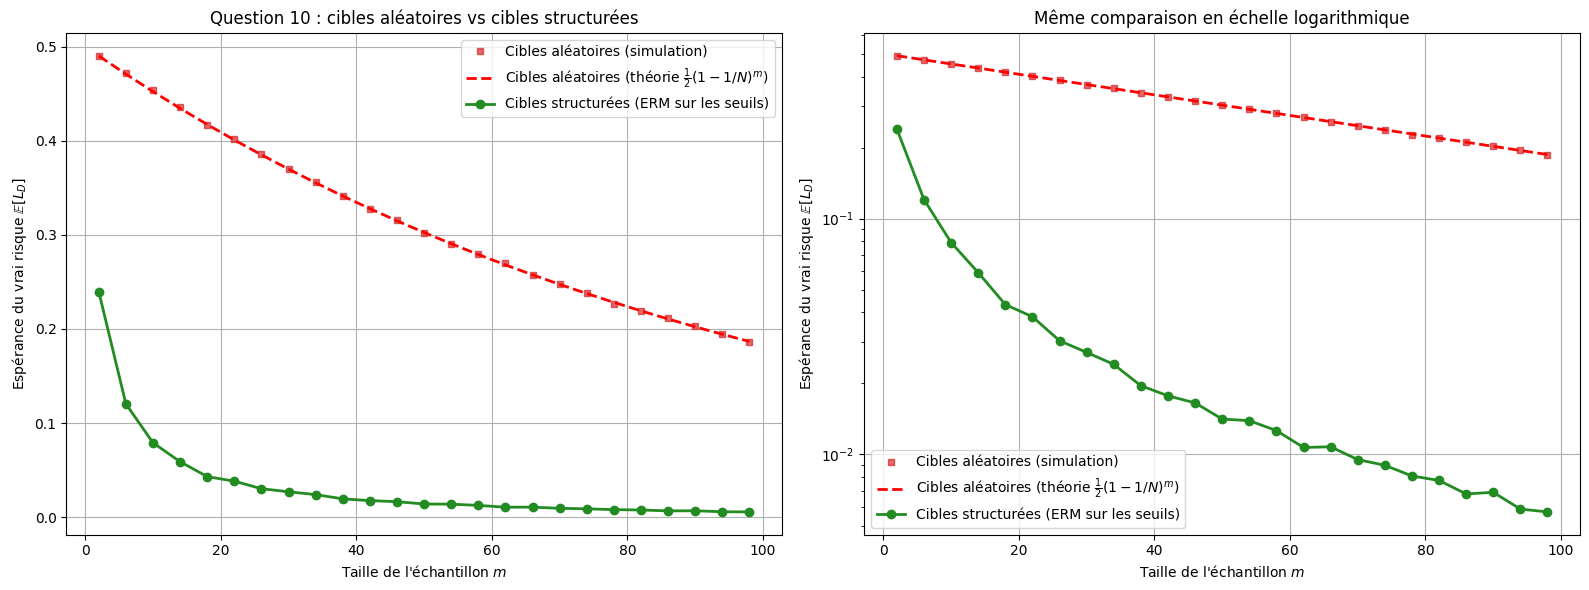

   m | cibles aléatoires | cibles structurées (seuils) | rapport aléatoire/structuré | m x risque structuré
   2 |      0.4904       |          0.2396            |              2.0            |        0.48
   6 |      0.4716       |          0.1203            |              3.9            |        0.72
  10 |      0.4540       |          0.0792            |              5.7            |        0.79
  22 |      0.4016       |          0.0384            |             10.5            |        0.84
  42 |      0.3280       |          0.0177            |             18.5            |        0.74
  62 |      0.2697       |          0.0107            |             25.2            |        0.66
  98 |      0.1867       |          0.0057            |             32.7            |        0.56


In [17]:
# Partie III 
np.random.seed(6)

N = 100
m_values_pt3 = np.arange(2, 101, 4)
n_simulations = 2000
thresholds = np.arange(1, N)             

exp_risk_structured = []
exp_risk_random = []

print("=== Partie III : Apprentissage ERM sur fonctions seuils en cours ===")

for m in m_values_pt3:
    risk_list = []

    for _ in range(n_simulations):
        # Question 9 (a) 
        theta = np.random.randint(1, N)

        # Question 9 (b) 
        S_x = np.random.randint(1, N + 1, size=m)
        S_y = (S_x > theta).astype(int)

        # Question 9 (c) : ERM. On calcule le nombre d'erreurs de chaque seuil t d'un coup,
        # puis on garde un seuil qui en fait le moins (argmin = le plus petit en cas d'égalité)
        preds = (S_x[None, :] > thresholds[:, None]).astype(int)     
        errors = np.sum(preds != S_y[None, :], axis=1)
        best_t = thresholds[np.argmin(errors)]

        # Question 9 (d) 
        risk_list.append(np.abs(theta - best_t) / N)

    exp_risk_structured.append(np.mean(risk_list))
    risk_rand_list = []
    for _ in range(n_simulations):
        f_target = np.random.binomial(1, 0.5, size=N)
        seen = np.unique(np.random.randint(0, N, size=m))
        pred = np.zeros(N)
        pred[seen] = f_target[seen]
        risk_rand_list.append(np.mean(pred != f_target))
    exp_risk_random.append(np.mean(risk_rand_list))

exp_risk_structured = np.array(exp_risk_structured)
exp_risk_random = np.array(exp_risk_random)
theo_risk_random = 0.5 * (1 - 1 / N) ** m_values_pt3

# Question 10 : comparaison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for ax in (ax1, ax2):
    ax.plot(m_values_pt3, exp_risk_random, 's', color='tab:red', markersize=4, alpha=0.7, label="Cibles aléatoires (simulation)")
    ax.plot(m_values_pt3, theo_risk_random, '--', color='red', linewidth=2, label=r"Cibles aléatoires (théorie $\frac{1}{2}(1-1/N)^m$)")
    ax.plot(m_values_pt3, exp_risk_structured, 'o-', color='forestgreen', linewidth=2, label="Cibles structurées (ERM sur les seuils)")
    ax.set_xlabel("Taille de l'échantillon $m$")
    ax.set_ylabel(r"Espérance du vrai risque $\mathbb{E}[L_D]$")
    ax.legend()
ax1.set_title("Question 10 : cibles aléatoires vs cibles structurées")
ax2.set_yscale('log')
ax2.set_title("Même comparaison en échelle logarithmique")
plt.tight_layout()
plt.show()

print("   m | cibles aléatoires | cibles structurées (seuils) | rapport aléatoire/structuré | m x risque structuré")
for m, ra, rs in zip(m_values_pt3, exp_risk_random, exp_risk_structured):
    if m in (2, 6, 10, 22, 42, 62, 98):
        print(f"{m:4d} |      {ra:.4f}       |          {rs:.4f}            |           {ra / rs:6.1f}            |        {m * rs:.2f}")

### Discussion des Questions 9 et 10

**Question 9 – Apprendre avec un biais inductif adapté.** Avec très peu d'exemples, l'ERM sur les seuils obtient déjà un risque faible : 0,12 à $m = 6$, 0,079 à $m = 10$, 0,038 à $m = 22$, 0,0057 à $m = 98$. Ces chiffres sont à mettre en regard de la Partie II où, pour les mêmes $N = 100$ et $m$, la mémorisation sur cible aléatoire donne :

| $m$ | cibles aléatoires | cibles structurées | rapport |
|---|---|---|---|
| 10 | 0,454 | 0,079 | 5,7 |
| 22 | 0,402 | 0,038 | 10,5 |
| 62 | 0,270 | 0,011 | 25 |
| 98 | 0,187 | 0,0057 | 33 |

Dès 10 exemples (10 % du domaine) le risque structuré est presque six fois plus faible. Pour atteindre le risque que le cas structuré obtient à $m = 98$, soit 0,0057, la mémorisation sur cibles aléatoires aurait besoin d'environ 445 exemples ($\frac12 \cdot 0{,}99^m = 0{,}0057$), soit quatre à cinq fois plus, et rappelons que le domaine ne contient que 100 points.

La décroissance du risque structuré est de l'ordre de $1/m$ : le produit $m \times \text{risque}$ reste entre 0,7 et 0,85 pour $m$ de 6 à 42. Plus loin il baisse (0,66 puis 0,56), ce qui est normal : quand $m$ approche $N$, l'échantillon couvre une grande partie du petit domaine et le seuil est presque exactement identifié. À l'inverse, la décroissance en cible aléatoire est celle du No-Free-Lunch, en $(1-1/N)^m$, qui n'est qu'une affaire de couverture du domaine.

**Question 10 – Pourquoi la généralisation devient possible.** La figure l'illustre, surtout en échelle logarithmique à droite : les deux courbes n'ont pas du tout le même comportement. Voici pourquoi.

- Dans le cas aléatoire, un exemple $(x, f(x))$ ne dit **rien** sur les autres points : chaque étiquette est indépendante. L'information apprise est strictement locale, et généraliser aux points non vus est impossible.
- Dans le cas des seuils, un seul exemple dit beaucoup. Si $f(x) = 0$, alors on sait que **tous** les points $\le x$ sont aussi à 0 ; si $f(x) = 1$, tous les points $> x$ sont à 1. Un exemple « couvre » donc tout un intervalle. Le seuil $\theta$ n'est caché que dans l'écart entre le plus grand point étiqueté 0 et le plus petit étiqueté 1, et cet écart rétrécit environ comme $1/m$ à mesure qu'on ajoute des exemples.

Le rôle de l'hypothèse « la cible appartient à la famille des seuils » est central, et je le vois sous deux angles. D'abord elle restreint énormément l'espace des possibles : $N - 1 = 99$ hypothèses au lieu de $2^{100}$ fonctions, donc moins d'hypothèses à départager. C'est la même logique que celle de la Partie I, où la taille de la classe fixe le nombre d'exemples nécessaires. Ensuite elle est **vraie** ici (la cible est dans la classe), ce qui permet à l'ERM de trouver un seuil à zéro erreur d'entraînement, et ce seuil est forcément proche de la cible. Si cette hypothèse était fausse, le biais ne servirait à rien : pour une cible tirée au hasard, n'importe quelle hypothèse fixe de la classe a un risque moyen de 1/2 (c'est le calcul de la Question 7), donc l'ERM sur les seuils ne ferait pas mieux qu'environ 0,5, quel que soit $m$. Le biais inductif n'est utile que s'il est adapté au problème.

---
## Question 11 – Conclusion

**Concentration de $L_S$ autour de $L_D$.** Le risque empirique est un estimateur sans biais du vrai risque et son écart-type vaut $\sqrt{p(1-p)/m}$ : la dispersion diminue en $1/\sqrt{m}$, ce qui est visible dès la Question 1 et se traduit par une probabilité de dépassement qui décroît exponentiellement en $m$ (Hoeffding, Question 2). Il faut quand même de l'ordre de plusieurs centaines d'exemples pour une précision de 5 points.

**Pourquoi il faut contrôler toutes les hypothèses à la fois.** Un algorithme comme l'ERM choisit l'hypothèse qui a l'air la meilleure sur l'échantillon, donc potentiellement celle qui a eu de la chance. Pour qu'il ne se trompe pas, il faut qu'aucune hypothèse ne soit mal estimée, d'où la nécessité de borner $\Delta_S = \max_h |L_S(h) - L_D(h)|$. Et le maximum est bien pire qu'une hypothèse isolée : à $m = 500$, 1 % de chances de dépasser $\varepsilon$ pour une hypothèse, 25 % pour la classe de 20 (Question 3).

**Effet de $|\mathcal{H}|$ et pessimisme des bornes.** Plus la classe est grande, plus il y a d'occasions de se tromper, et la courbe de $\Pr[\Delta_S > \varepsilon]$ se décale vers la droite. Le coût en données est toutefois seulement **logarithmique** : multiplier la classe par 100 n'a demandé qu'environ 2,4 fois plus d'exemples (Questions 4 et 5). Les bornes théoriques décrivent bien cette dépendance mais restent conservatrices, de l'ordre d'un facteur 1,5 à 2 sur $m$ et bien davantage sur les probabilités, parce qu'elles valent dans le pire cas, ignorent la variance et additionnent les événements par l'union. Il faut les lire comme des garanties suffisantes, pas comme des prédictions.

**No-Free-Lunch.** Quand la cible est un tirage uniforme parmi toutes les fonctions, un exemple n'apporte aucune information sur les autres points : sur un point non vu, la bonne étiquette est un pile ou face. Le risque de l'algorithme par mémorisation est alors exactement $\frac12(1-1/N)^m$, soit la moitié de la fraction de points non vus, et il ne diminue que parce que l'échantillon finit par recouvrir tout le domaine. Aucune des règles testées (prédire 0, 1 ou au hasard) ne fait mieux qu'une autre, et le complément de la Question 8 montre que chacune gagne dans certains mondes et perd dans d'autres. Un apprenant ne peut donc pas déduire des étiquettes arbitraires inconnues à partir de l'échantillon seul.

**Biais inductif.** Restreindre cibles et hypothèses aux seuils change tout : $f(x)$ renseigne sur tout un intervalle, la classe est petite, et l'ERM atteint un risque de l'ordre de $1/m$ au lieu de $\frac12 e^{-m/N}$, avec par exemple 0,079 contre 0,454 pour $m = 10$. L'apprenant généralise au-delà des points observés, mais uniquement parce qu'on lui a dit, par le choix de la classe, quel type de régularité chercher. S'il était faux, ce biais ne servirait à rien. **On ne peut pas apprendre sans hypothèse a priori, mais avec la bonne, quelques exemples suffisent.**

*Limites de l'étude.* Les résultats sont des estimations Monte-Carlo avec une graine fixée (l'incertitude est de l'ordre de $10^{-3}$ à $10^{-2}$ sur les probabilités estimées), la partie I suppose des hypothèses aux erreurs indépendantes, et les parties II et III travaillent sur un domaine fini de petite taille. Les tendances et les ordres de grandeur sont, eux, robustes à ces choix.